<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Decision Tree Classifier on Heart Failure Prediction Dataset

We will load the dataset, pre-process it by encoding categorical variables, split the data into training and testing sets, train a Decision Tree Classifier, and evaluate its performance.

In [12]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score

# Automatically search for 'heart.csv' or similar matching filenames
search_paths = glob.glob('**/heart*.csv', recursive=True) + glob.glob('**/*/heart*.csv', recursive=True)

data_path = None
if search_paths:
    # Choose the first matching path found
    data_path = search_paths[0]
    print(f"Found dataset dynamically at: {data_path}")
else:
    # Fallback paths to test explicitly
    explicit_paths = [
        '../input/heart-failure-prediction/heart.csv',
        'heart.csv',
        '/kaggle/input/heart-failure-prediction/heart.csv'
    ]
    for path in explicit_paths:
        if os.path.exists(path):
            data_path = path
            break

if data_path:
    df = pd.read_csv(data_path)
    print(f"Successfully loaded dataset from: {data_path}")
    display(df.head())
else:
    raise FileNotFoundError("Could not automatically locate the heart failure dataset CSV. Please make sure the dataset is uploaded or mounted correctly.")

Found dataset dynamically at: heart.csv
Successfully loaded dataset from: heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [13]:
# Clean and prepare dataset
# Target column is usually 'HeartDisease' in this dataset
target_col = 'HeartDisease' if 'HeartDisease' in df.columns else df.columns[-1]
print(f"Target column chosen: {target_col}")

# Separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

# One-hot encode categorical variables
X_encoded = pd.get_dummies(X, drop_first=True)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# Predictions and evaluation
y_pred = clf.predict(X_test)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Target column chosen: HeartDisease
Accuracy Score: 0.8750

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.87      0.85        77
           1       0.90      0.88      0.89       107

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



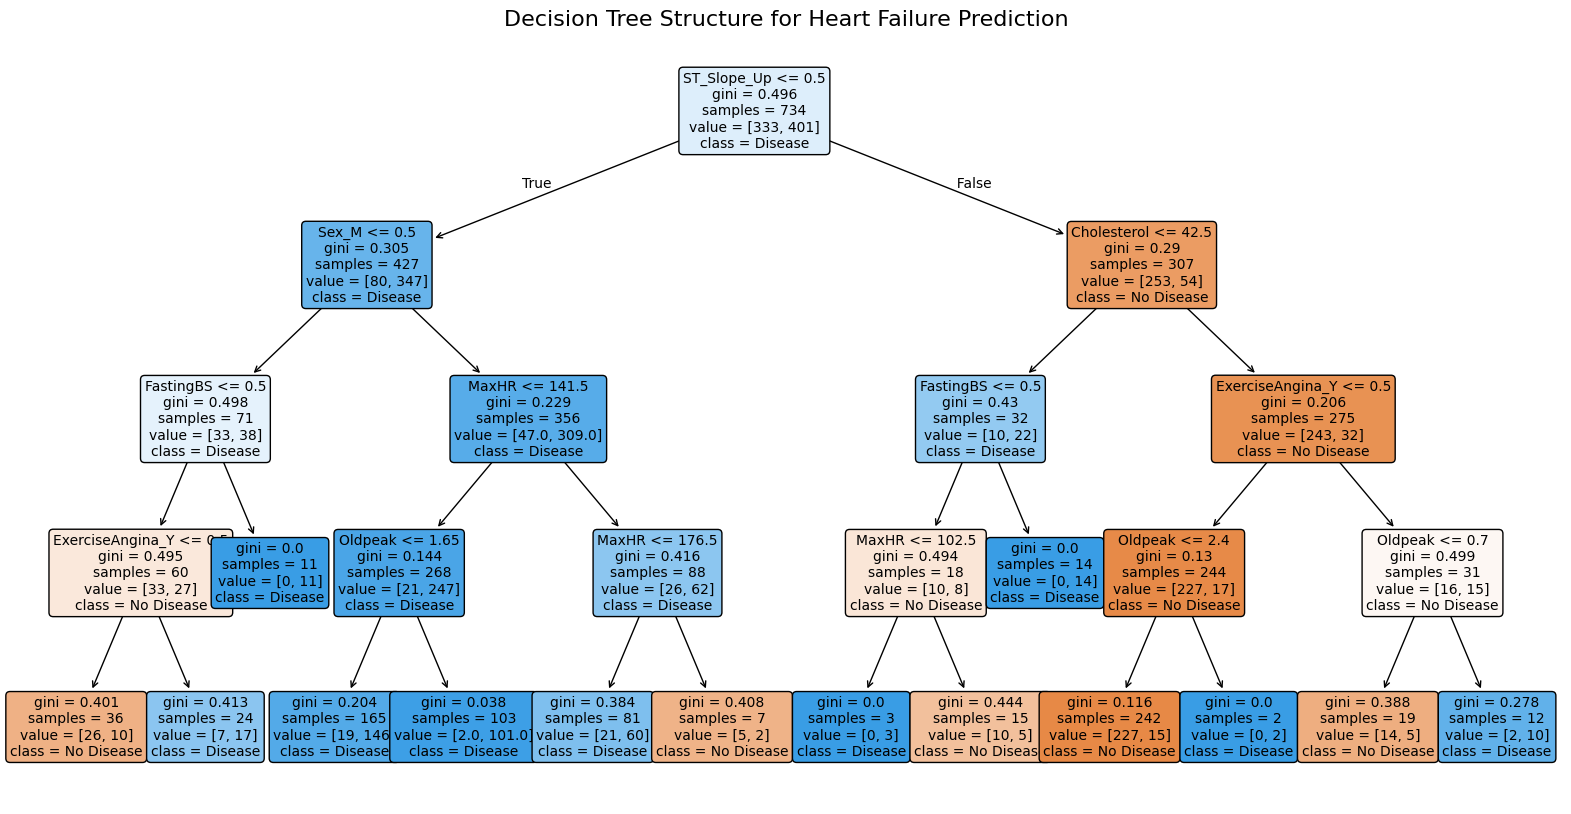

In [14]:
# Plot the decision tree structure
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=X_encoded.columns,
    class_names=['No Disease', 'Disease'] if target_col == 'HeartDisease' else True,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure for Heart Failure Prediction", fontsize=16)
plt.show()